# **Projet : Intelligence artificielle avec le son**

## Partie A : Caractéristiques générales du son

0. Introduction au son wav

1. Analyse de l'amplitude au cours du temps avec un osciloscope

2. Analyse des fréquences à un instant donnée grace à la Transformation de Fourier

3. Analys de l'évolution de la fréquence dans le temps à l'aide du spectrogramme et du spectrogramme MEL .


## Partie B : Caractéristiques particulières du son




---



---



## Partie A : Caractéristiques générales du son

0. Introduction au son wav

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [ ]:
audio_path = "test.wav"
signal, sr = librosa.load(audio_path)

In [ ]:
print("Taille du signal :", signal.shape)
print("Sampling rate :", sr)

Taille du signal : (259088,)
Sampling rate : 22050


In [ ]:
print("Taille du signal :", signal.shape)
print("Sampling rate :", sr)

Taille du signal : (259088,)
Sampling rate : 22050


1. Analyse de l'amplitude au cours du temps avec un osciloscope

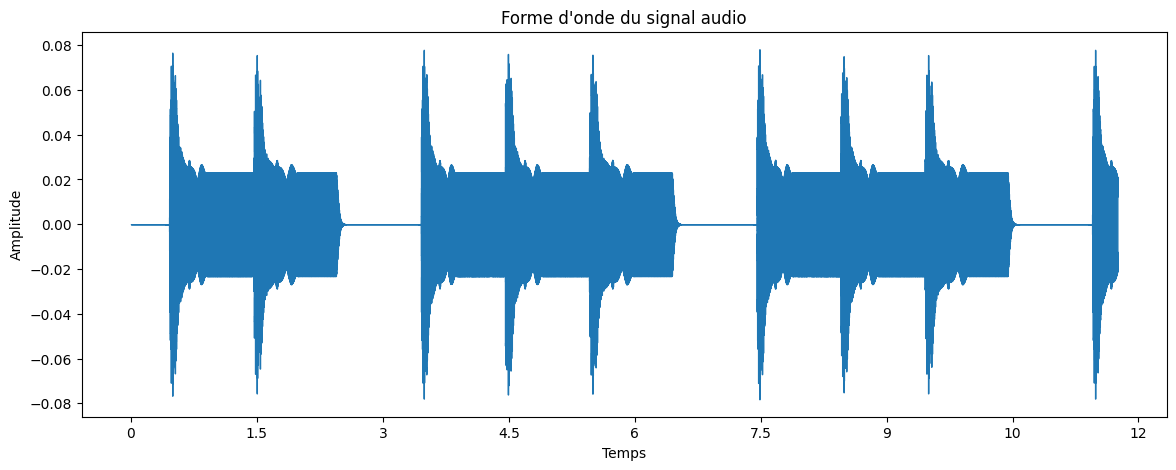

In [ ]:
plt.figure(figsize=(14, 5))
librosa.display.waveshow(signal, sr=sr)
# ces 2 mesure nous donne l'amplitude dans le temps
plt.title("Forme d'onde du signal audio")
plt.xlabel("Temps")
plt.ylabel("Amplitude")
plt.show()

2. Analyse des fréquences à un instant donnée grace à la Transformation de Fourier

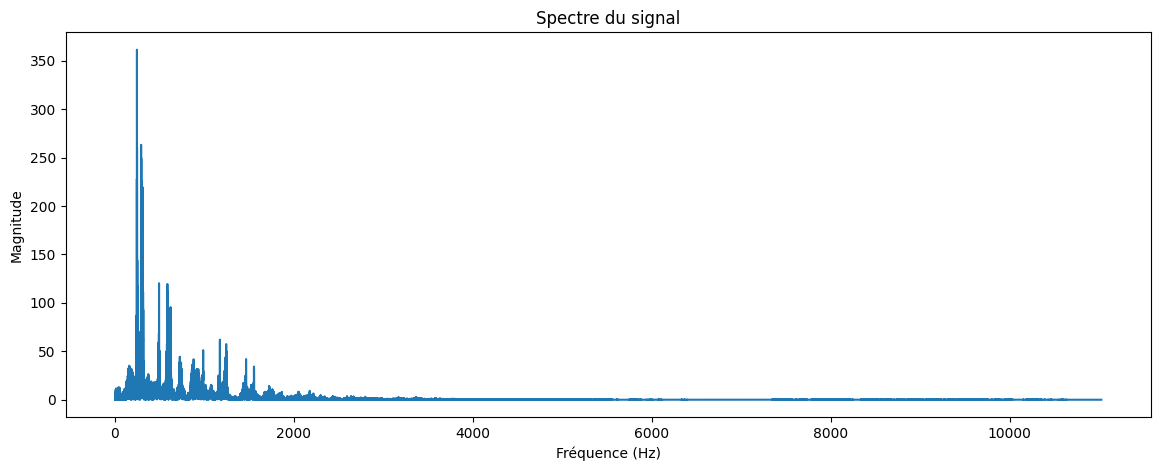

In [ ]:
import numpy as np
fft = np.fft.fft(signal)
magnitude = np.abs(fft)
frequency = np.linspace(0, sr, len(magnitude))
plt.figure(figsize=(14, 5))
plt.plot(frequency[:len(frequency)//2], magnitude[:len(magnitude)//2])
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Magnitude")
plt.title("Spectre du signal")
plt.show()

3. Analys de l'évolution de la fréquence dans le temps à l'aide du spectrogramme et du spectrogramme MEL .

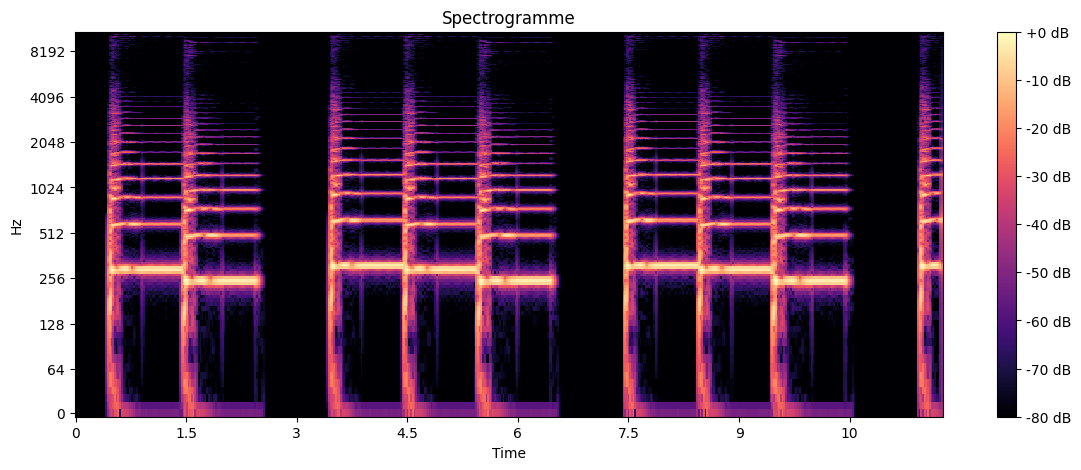

In [ ]:
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
signal, sr = librosa.load("test.wav")
stft = librosa.stft(signal)
spectrogram = np.abs(stft)
log_spec = librosa.amplitude_to_db(spectrogram, ref=np.max)
plt.figure(figsize=(14, 5))
librosa.display.specshow(log_spec, sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogramme")
plt.show()

In [ ]:
mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=128)
log_mel = librosa.power_to_db(mel, ref=np.max)
librosa.display.specshow(log_mel, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel-spectrogramme")
plt.show()

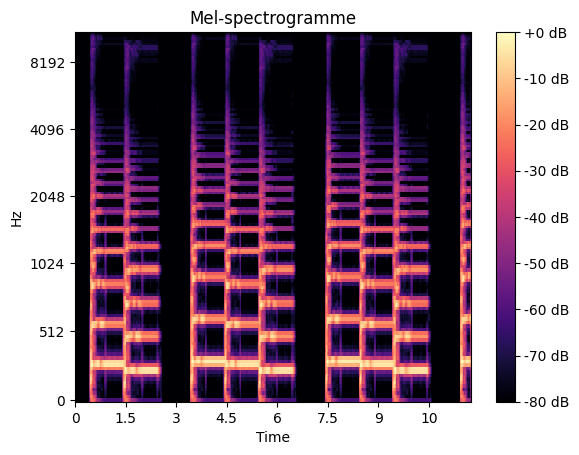

In [ ]:
mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=128)
log_mel = librosa.power_to_db(mel, ref=np.max)
librosa.display.specshow(log_mel, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel-spectrogramme")
plt.show()

## Partie B : Caractéristiques particulières du son

Zero Crossing Rate (ZCR)

In [ ]:
import librosa
signal, sr = librosa.load("test.wav")
zcr = librosa.feature.zero_crossing_rate(signal)
print("Shape :", zcr.shape)
print("Moyenne ZCR :", zcr.mean())

Shape : (1, 507)
Moyenne ZCR : 0.03125096307938856


Spectral Centroid

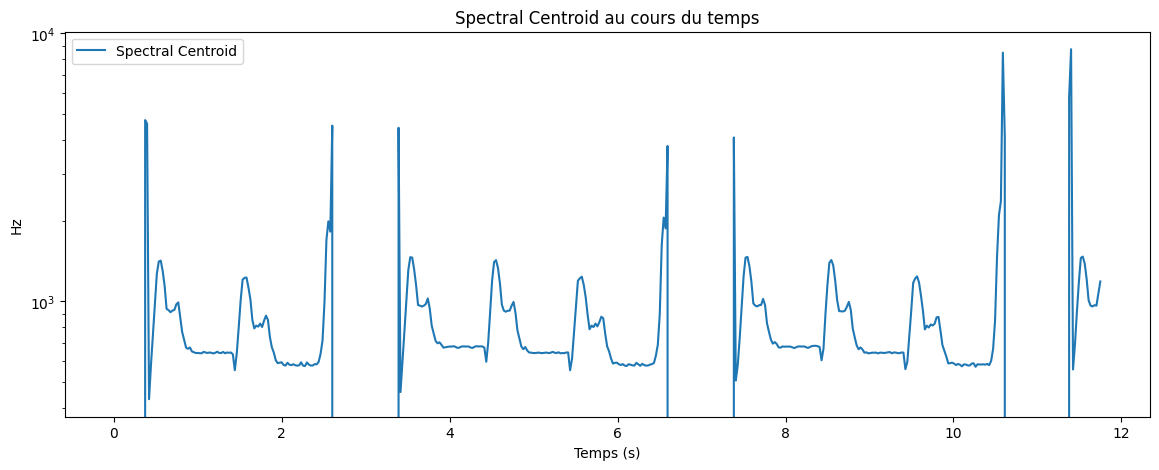

In [ ]:
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
signal, sr = librosa.load("test.wav")
centroid = librosa.feature.spectral_centroid(y=signal, sr=sr)[0]
frames = range(len(centroid))
t = librosa.frames_to_time(frames, sr=sr)
plt.figure(figsize=(14, 5))
plt.semilogy(t, centroid, label="Spectral Centroid")
plt.xlabel("Temps (s)")
plt.ylabel("Hz")
plt.title("Spectral Centroid au cours du temps")
plt.legend()
plt.show()